<a href="https://colab.research.google.com/github/olfaelshiekh/ECG-Arrhythmia-Analysis/blob/main/ECG_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install wfdb numpy pandas matplotlib scipy

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import wfdb

print("ECG Project Environment Ready!")

ECG Project Environment Ready!


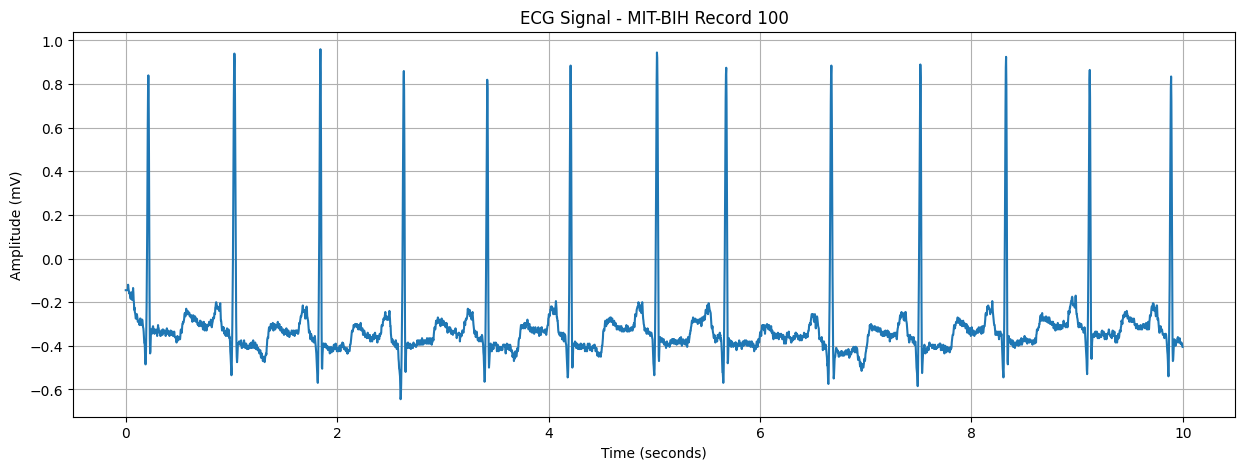

Sampling Frequency: 360 Hz
Number of Samples: 3600
Duration: 10.0 seconds


In [3]:
import wfdb
import numpy as np
import matplotlib.pyplot as plt

# Load ECG record 100 from MIT-BIH
record = wfdb.rdrecord('100', pn_dir='mitdb', sampto=3600)

# Extract ECG signal
ecg_signal = record.p_signal[:, 0]

# Sampling frequency
fs = record.fs

# Create time axis
time = np.arange(len(ecg_signal)) / fs

# Plot ECG signal
plt.figure(figsize=(15, 5))
plt.plot(time, ecg_signal)

plt.title('ECG Signal - MIT-BIH Record 100')
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude (mV)')
plt.grid(True)

plt.show()

print("Sampling Frequency:", fs, "Hz")
print("Number of Samples:", len(ecg_signal))
print("Duration:", len(ecg_signal) / fs, "seconds")

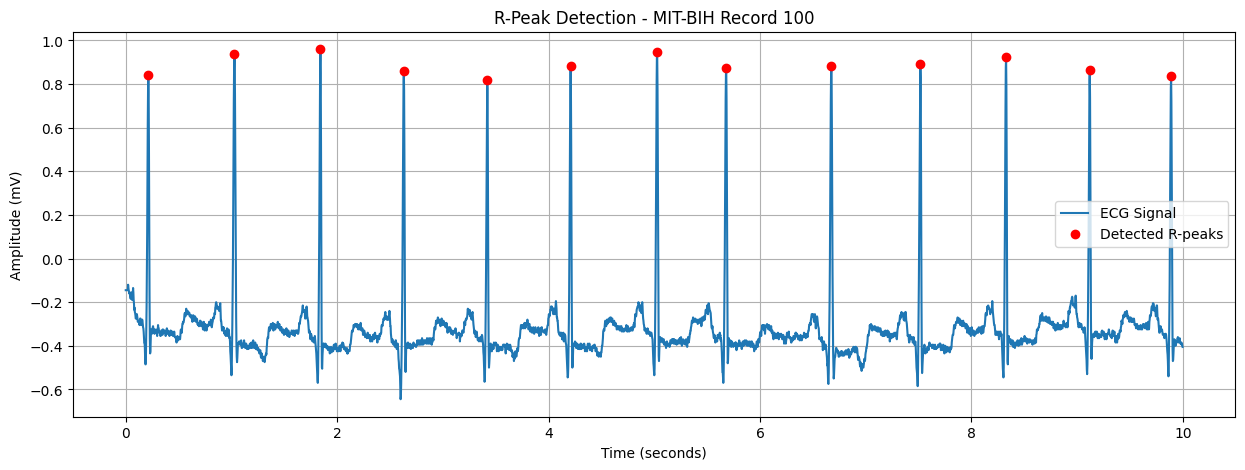

Detected R-peaks: 13
Mean RR Interval: 0.8062499999999999
Mean Heart Rate: 74.99723655197333 BPM


In [4]:
from scipy.signal import find_peaks

# Detect R-peaks
peaks, properties = find_peaks(
    ecg_signal,
    distance=int(0.4 * fs),
    prominence=0.5
)

# Calculate RR intervals
rr_intervals = np.diff(peaks) / fs

# Calculate heart rate
heart_rates = 60 / rr_intervals

# Plot ECG with detected R-peaks
plt.figure(figsize=(15, 5))

plt.plot(time, ecg_signal, label='ECG Signal')
plt.plot(time[peaks], ecg_signal[peaks], 'ro',
         label='Detected R-peaks')

plt.title('R-Peak Detection - MIT-BIH Record 100')
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude (mV)')
plt.legend()
plt.grid()

plt.show()

print("Detected R-peaks:", len(peaks))
print("Mean RR Interval:", np.mean(rr_intervals))
print("Mean Heart Rate:", np.mean(heart_rates), "BPM")

RR Intervals (ms):
Interval 1: 813.89 ms
Interval 2: 813.89 ms
Interval 3: 788.89 ms
Interval 4: 788.89 ms
Interval 5: 788.89 ms
Interval 6: 816.67 ms
Interval 7: 655.56 ms
Interval 8: 994.44 ms
Interval 9: 841.67 ms
Interval 10: 811.11 ms
Interval 11: 791.67 ms
Interval 12: 769.44 ms


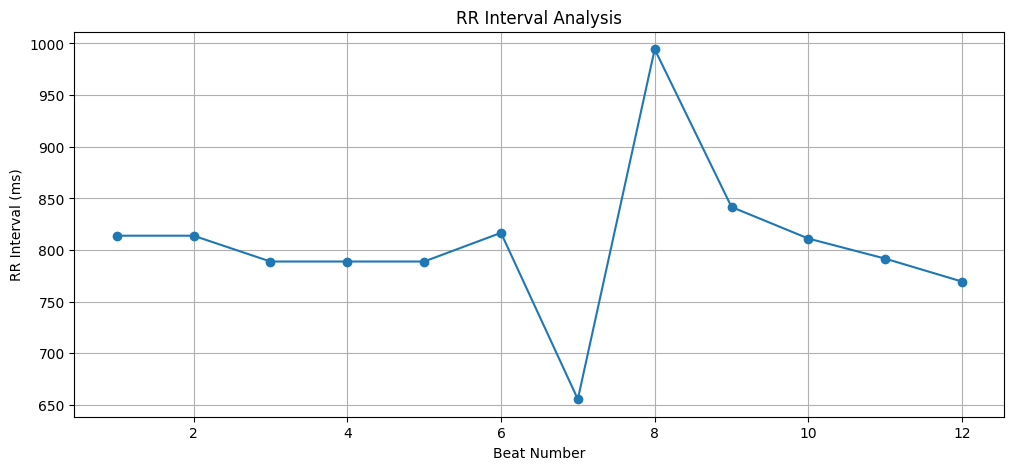

Mean RR: 806.2500000000001 ms
RR Standard Deviation: 71.93787507544528 ms


In [5]:
# Calculate RR intervals in milliseconds
rr_ms = rr_intervals * 1000

# Display RR intervals
print("RR Intervals (ms):")

for i, rr in enumerate(rr_ms):
    print(f"Interval {i+1}: {rr:.2f} ms")

# Plot RR intervals
plt.figure(figsize=(12, 5))

plt.plot(range(1, len(rr_ms)+1), rr_ms, marker='o')

plt.title("RR Interval Analysis")
plt.xlabel("Beat Number")
plt.ylabel("RR Interval (ms)")
plt.grid(True)

plt.show()

# Calculate variability
print("Mean RR:", np.mean(rr_ms), "ms")
print("RR Standard Deviation:", np.std(rr_ms), "ms")

In [7]:
# HRV Analysis

# Convert RR intervals to milliseconds
rr_ms = rr * 1000

# 1. Mean RR
mean_rr = np.mean(rr_ms)

# 2. SDNN
SDNN = np.std(rr_ms, ddof=1)

# 3. RMSSD
differences = np.diff(rr_ms)
RMSSD = np.sqrt(np.mean(differences**2))

# 4. pNN50
NN50 = np.sum(np.abs(differences) > 50)
pNN50 = (NN50 / len(differences)) * 100

# Display results
print("===== HRV Analysis =====")
print("Mean RR:", mean_rr, "ms")
print("SDNN:", SDNN, "ms")
print("RMSSD:", RMSSD, "ms")
print("pNN50:", pNN50, "%")

===== HRV Analysis =====
Mean RR: 806.2500000000001 ms
SDNN: 75.136660005404 ms
RMSSD: 123.3419780390151 ms
pNN50: 27.27272727272727 %


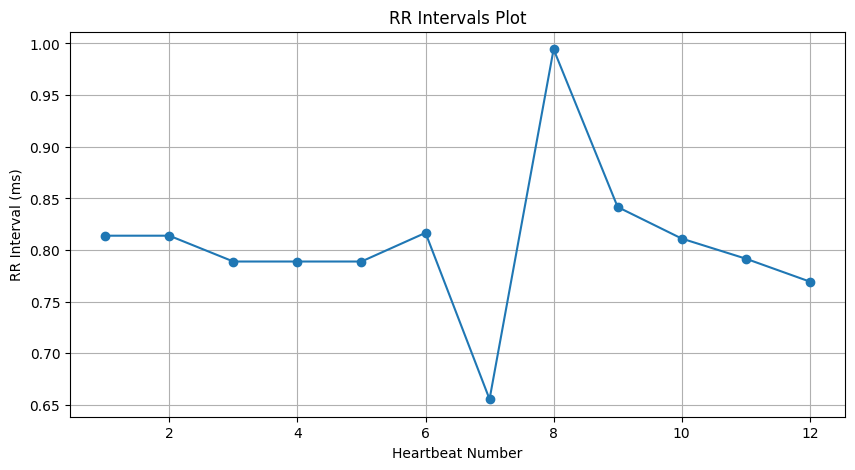

In [8]:
import matplotlib.pyplot as plt
import numpy as np

# RR Intervals Plot

plt.figure(figsize=(10, 5))

plt.plot(range(1, len(rr_intervals) + 1),
         rr_intervals, marker='o')

plt.title("RR Intervals Plot")
plt.xlabel("Heartbeat Number")
plt.ylabel("RR Interval (ms)")
plt.grid(True)

plt.show()

In [9]:
import numpy as np

# Convert RR intervals to milliseconds
rr = np.array(rr_intervals)

if np.mean(rr) < 10:
    rr = rr * 1000

# Calculate HRV parameters
SDNN = np.std(rr, ddof=1)

RMSSD = np.sqrt(np.mean(np.diff(rr)**2))

NN50 = np.sum(np.abs(np.diff(rr)) > 50)

pNN50 = (NN50 / len(np.diff(rr))) * 100

# Display results
print("HRV Analysis Results")
print("--------------------")
print("SDNN:", round(SDNN, 2), "ms")
print("RMSSD:", round(RMSSD, 2), "ms")
print("NN50:", NN50)
print("pNN50:", round(pNN50, 2), "%")

HRV Analysis Results
--------------------
SDNN: 75.14 ms
RMSSD: 123.34 ms
NN50: 3
pNN50: 27.27 %


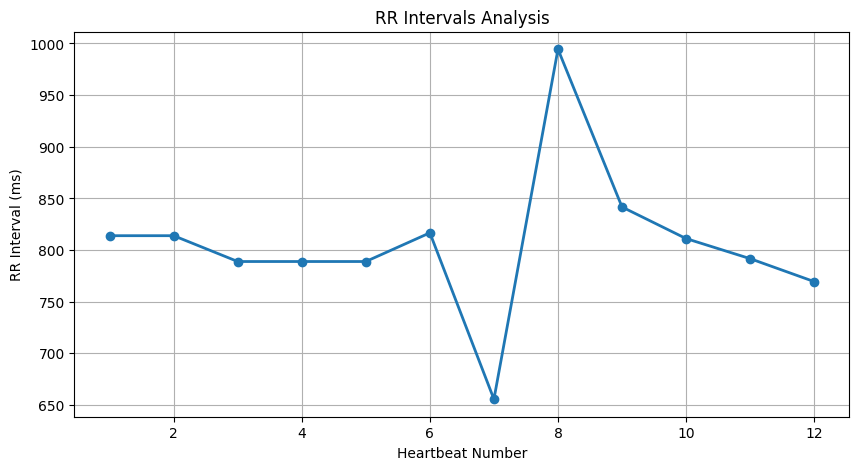

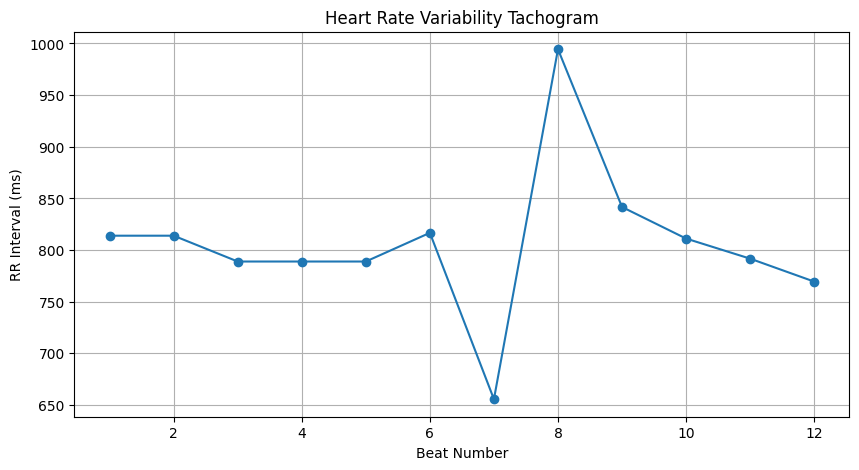

In [10]:
import matplotlib.pyplot as plt
import numpy as np

# Convert RR intervals to array
rr_ms = np.array(rr)

# 1. RR Intervals Plot
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(rr_ms) + 1),
    rr_ms,
    marker='o',
    linewidth=2
)

plt.title("RR Intervals Analysis")
plt.xlabel("Heartbeat Number")
plt.ylabel("RR Interval (ms)")
plt.grid(True)

plt.show()


# 2. HRV Tachogram
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(rr_ms) + 1),
    rr_ms,
    marker='o',
    linestyle='-'
)

plt.title("Heart Rate Variability Tachogram")
plt.xlabel("Beat Number")
plt.ylabel("RR Interval (ms)")
plt.grid(True)

plt.show()

In [13]:
# Convert RR intervals to milliseconds
rr_intervals_ms = rr_intervals * 1000

# 1. SDNN
sdnn = np.std(rr_intervals_ms, ddof=1)

# 2. RMSSD
successive_differences = np.diff(rr_intervals_ms)
rmssd = np.sqrt(np.mean(successive_differences**2))

# 3. pNN50
nn50 = np.sum(np.abs(successive_differences) > 50)
pnn50 = (nn50 / len(successive_differences)) * 100

# Display results
print("HRV Analysis Results")
print("----------------------")
print(f"SDNN: {sdnn:.2f} ms")
print(f"RMSSD: {rmssd:.2f} ms")
print(f"pNN50: {pnn50:.2f}%")

HRV Analysis Results
----------------------
SDNN: 75.14 ms
RMSSD: 123.34 ms
pNN50: 27.27%


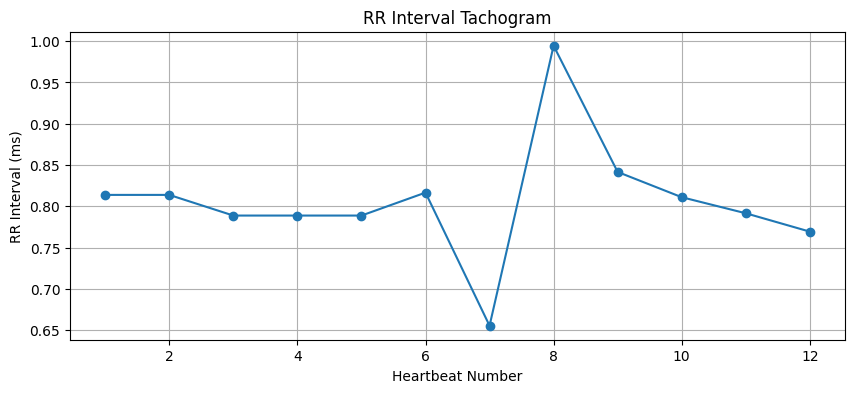

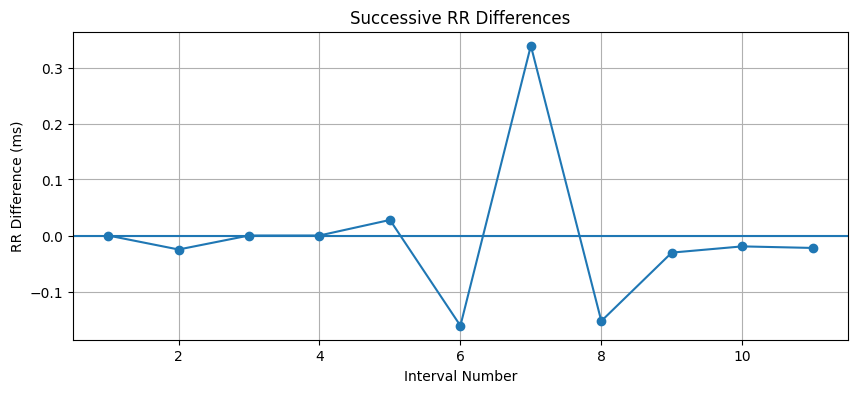

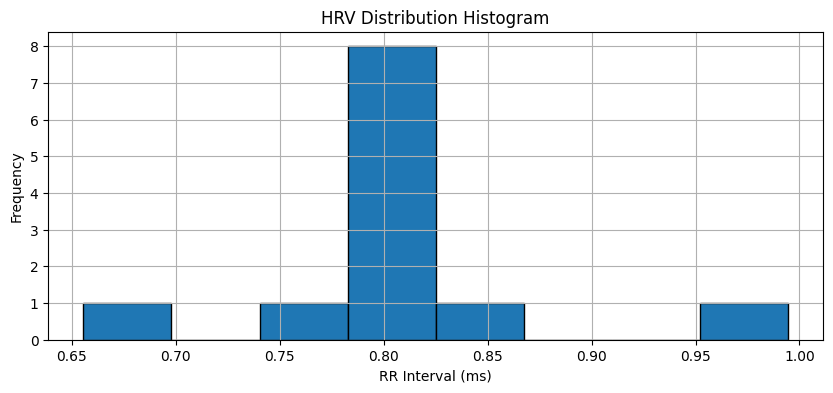

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# Convert RR intervals to numpy array
rr = np.array(rr_intervals)

# 1. RR Interval Tachogram
plt.figure(figsize=(10, 4))

plt.plot(range(1, len(rr) + 1), rr, marker='o')

plt.title("RR Interval Tachogram")
plt.xlabel("Heartbeat Number")
plt.ylabel("RR Interval (ms)")
plt.grid(True)

plt.show()


# 2. Successive RR Differences
rr_diff = np.diff(rr)

plt.figure(figsize=(10, 4))

plt.plot(range(1, len(rr_diff) + 1),
         rr_diff, marker='o')

plt.axhline(y=0)
plt.title("Successive RR Differences")
plt.xlabel("Interval Number")
plt.ylabel("RR Difference (ms)")
plt.grid(True)

plt.show()


# 3. HRV Distribution Histogram
plt.figure(figsize=(10, 4))

plt.hist(rr, bins=8, edgecolor='black')

plt.title("HRV Distribution Histogram")
plt.xlabel("RR Interval (ms)")
plt.ylabel("Frequency")
plt.grid(True)

plt.show()

In [27]:
# RR Interval Statistics

print("Mean RR:", np.mean(rr_ms), "ms")

print("Minimum RR:", np.min(rr_ms), "ms")

print("Maximum RR:", np.max(rr_ms), "ms")

print("Standard Deviation:", np.std(rr_ms), "ms")

Mean RR: 806.2500000000001 ms
Minimum RR: 655.5555555555555 ms
Maximum RR: 994.4444444444445 ms
Standard Deviation: 71.93787507544528 ms


In [17]:
print([x for x in globals() if "rr" in x.lower()])

['rr_intervals', 'rr_ms', 'rr', 'mean_rr', 'rr_intervals_ms', 'rr_diff']


In [18]:
print("Mean RR:", np.mean(rr_intervals))
print("Minimum RR:", np.min(rr_intervals))
print("Maximum RR:", np.max(rr_intervals))
print("RR Standard Deviation:", np.std(rr_intervals))

Mean RR: 0.8062499999999999
Minimum RR: 0.6555555555555556
Maximum RR: 0.9944444444444445
RR Standard Deviation: 0.07193787507544529


In [20]:
# Convert RR intervals to milliseconds
rr_ms = rr_intervals * 1000

# Calculate SDNN
SDNN = np.std(rr_ms, ddof=1)

# Calculate RMSSD
RMSSD = np.sqrt(np.mean(np.diff(rr_ms)**2))

# Calculate pNN50
differences = np.abs(np.diff(rr_ms))
pNN50pNN50 = np.sum(np.abs(differences) > 50) / len(differences) * 100

# Display results
print("HRV Analysis Results")
print("--------------------")
print("SDNN:", SDNN, "ms")
print("RMSSD:", RMSSD, "ms")
print("pNN50:", pNN50, "%")

HRV Analysis Results
--------------------
SDNN: 75.136660005404 ms
RMSSD: 123.3419780390151 ms
pNN50: 27.27272727272727 %


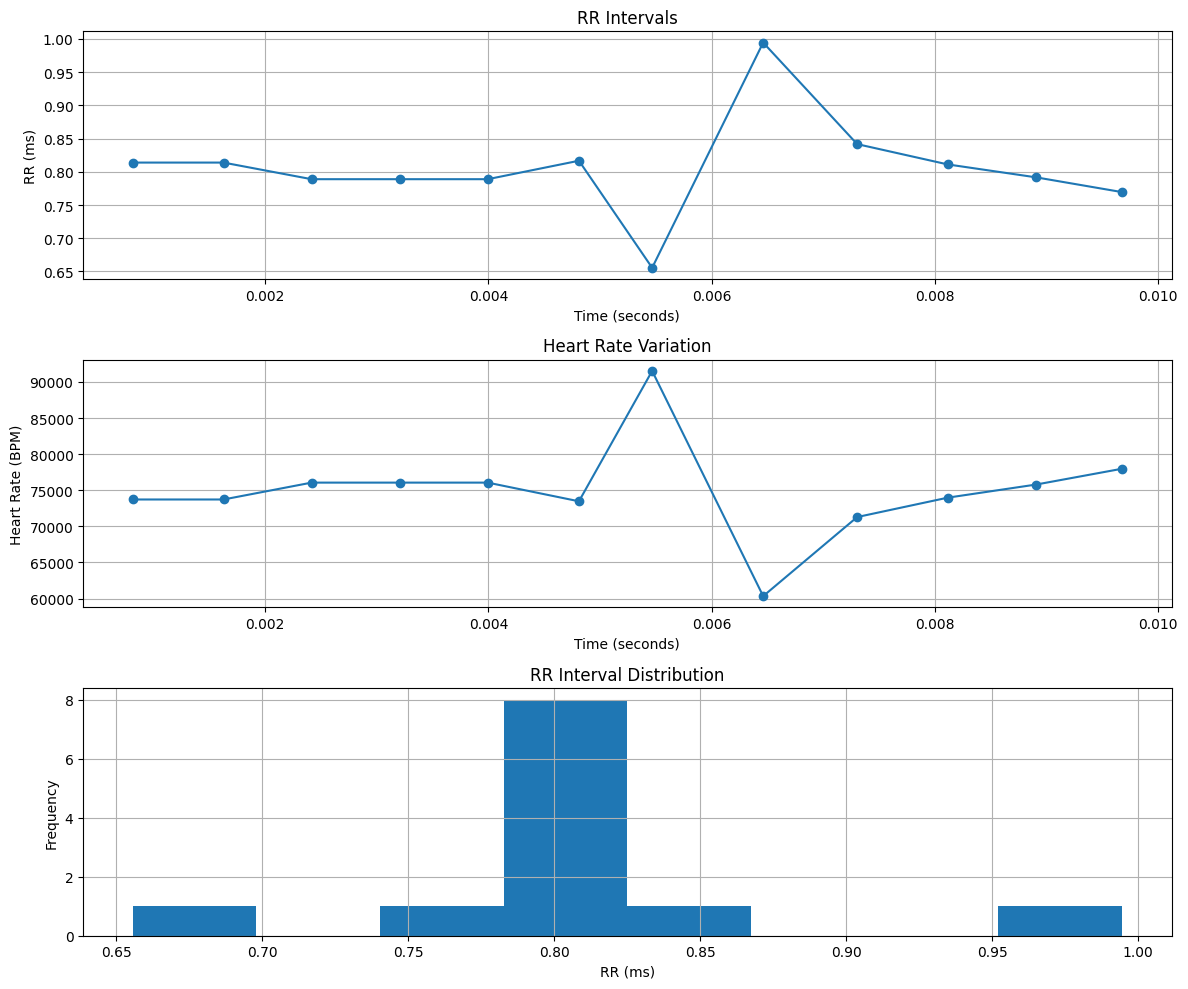

In [21]:
import numpy as np
import matplotlib.pyplot as plt

# RR Intervals (milliseconds)
rr = np.array(rr_intervals)

# Calculate instantaneous Heart Rate
heart_rate = 60000 / rr

# Calculate cumulative time
time = np.cumsum(rr) / 1000

# Create plots
plt.figure(figsize=(12, 10))

# Plot 1: RR Intervals
plt.subplot(3, 1, 1)
plt.plot(time, rr, marker='o')
plt.title('RR Intervals')
plt.xlabel('Time (seconds)')
plt.ylabel('RR (ms)')
plt.grid(True)

# Plot 2: Heart Rate
plt.subplot(3, 1, 2)
plt.plot(time, heart_rate, marker='o')
plt.title('Heart Rate Variation')
plt.xlabel('Time (seconds)')
plt.ylabel('Heart Rate (BPM)')
plt.grid(True)

# Plot 3: RR Interval Distribution
plt.subplot(3, 1, 3)
plt.hist(rr, bins=8)
plt.title('RR Interval Distribution')
plt.xlabel('RR (ms)')
plt.ylabel('Frequency')
plt.grid(True)

plt.tight_layout()
plt.show()

In [22]:
import numpy as np

# Convert RR intervals from seconds to milliseconds
rr_ms = np.array(rr_intervals) * 1000

# Calculate successive differences
rr_diff = np.diff(rr_ms)

# SDNN
sdnn = np.std(rr_ms, ddof=1)

# RMSSD
rmssd = np.sqrt(np.mean(rr_diff ** 2))

# pNN50
pnn50 = np.sum(np.abs(rr_diff) > 50) / len(rr_diff) * 100

# Display results
print("HRV Analysis Results")
print("--------------------")
print(f"SDNN: {sdnn:.2f} ms")
print(f"RMSSD: {rmssd:.2f} ms")
print(f"pNN50: {pnn50:.2f}%")

HRV Analysis Results
--------------------
SDNN: 75.14 ms
RMSSD: 123.34 ms
pNN50: 27.27%


In [23]:
# Inspect RR intervals

print("RR Intervals (ms):")
print(rr_ms)

print("\nSuccessive Differences (ms):")
print(rr_diff)

print("\nNumber of RR intervals:")
print(len(rr_ms))

print("\nNumber of differences:")
print(len(rr_diff))

RR Intervals (ms):
[813.88888889 813.88888889 788.88888889 788.88888889 788.88888889
 816.66666667 655.55555556 994.44444444 841.66666667 811.11111111
 791.66666667 769.44444444]

Successive Differences (ms):
[   0.          -25.            0.            0.           27.77777778
 -161.11111111  338.88888889 -152.77777778  -30.55555556  -19.44444444
  -22.22222222]

Number of RR intervals:
12

Number of differences:
11


In [24]:
# RR Interval Quality Assessment

print("RR Interval Quality Check")
print("-------------------------")

for i, rr in enumerate(rr_ms):
    print(f"Interval {i+1}: {rr:.2f} ms")

print("\nAbnormal Differences:")

for i, diff in enumerate(rr_diff):
    if abs(diff) > 50:
        print(f"Difference {i+1}: {diff:.2f} ms")

RR Interval Quality Check
-------------------------
Interval 1: 813.89 ms
Interval 2: 813.89 ms
Interval 3: 788.89 ms
Interval 4: 788.89 ms
Interval 5: 788.89 ms
Interval 6: 816.67 ms
Interval 7: 655.56 ms
Interval 8: 994.44 ms
Interval 9: 841.67 ms
Interval 10: 811.11 ms
Interval 11: 791.67 ms
Interval 12: 769.44 ms

Abnormal Differences:
Difference 6: -161.11 ms
Difference 7: 338.89 ms
Difference 8: -152.78 ms


In [29]:
print("len(ecg_signal):", len(ecg_signal))
print("len(time):", len(time))
print("time[:5]:", time[:5])
print("peaks:", peaks)

len(ecg_signal): 3600
len(time): 12
time[:5]: [0.00081389 0.00162778 0.00241667 0.00320556 0.00399444]
peaks: [  77  370  663  947 1231 1515 1809 2045 2403 2706 2998 3283 3560]


In [30]:
# R-Peak Verification - Final Fixed Version

# True sampling rate for this dataset
fs = 360

# Rebuild the correct time axis: 3600 points / 360 = 10 seconds
time_full = np.arange(len(ecg_signal)) / fs

print("Sampling Rate:", fs, "Hz")
print("Signal Length:", len(ecg_signal), "samples")
print("Duration:", len(ecg_signal) / fs, "seconds")

print("\nDetected R-peaks:", len(peaks))
print("\nPeak Times (seconds):")
print(time_full[peaks])
print("\nPeak Amplitudes:")
print(ecg_signal[peaks])
print("\nRR Intervals (ms):")
print(rr_ms)

Sampling Rate: 360 Hz
Signal Length: 3600 samples
Duration: 10.0 seconds

Detected R-peaks: 13

Peak Times (seconds):
[0.21388889 1.02777778 1.84166667 2.63055556 3.41944444 4.20833333
 5.025      5.68055556 6.675      7.51666667 8.32777778 9.11944444
 9.88888889]

Peak Amplitudes:
[0.84  0.94  0.96  0.86  0.82  0.885 0.945 0.875 0.885 0.89  0.925 0.865
 0.835]

RR Intervals (ms):
[813.88888889 813.88888889 788.88888889 788.88888889 788.88888889
 816.66666667 655.55555556 994.44444444 841.66666667 811.11111111
 791.66666667 769.44444444]


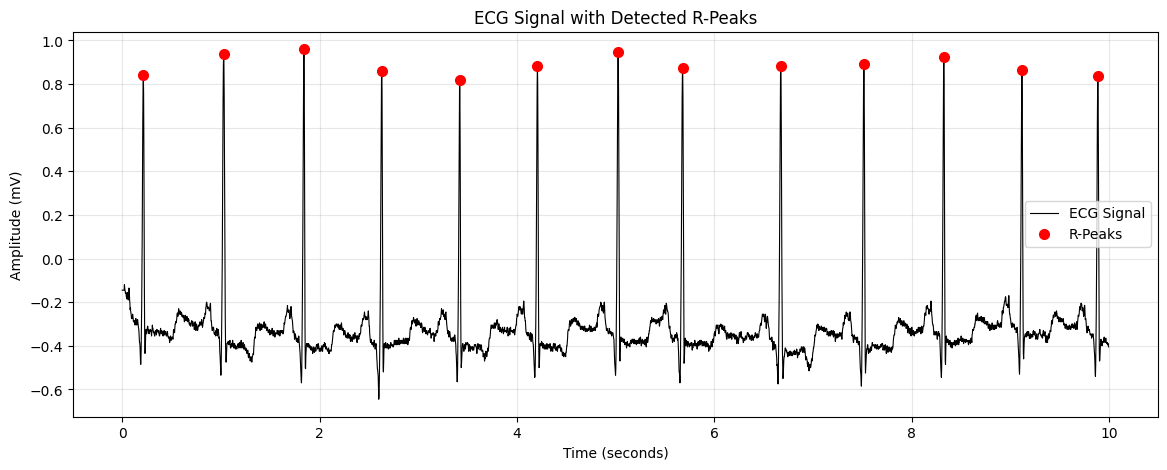

In [31]:
# Final ECG Plot with R-Peaks

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
plt.plot(time_full, ecg_signal, label='ECG Signal', color='black', linewidth=0.8)
plt.plot(time_full[peaks], ecg_signal[peaks], 'ro', label='R-Peaks', markersize=7)

plt.title('ECG Signal with Detected R-Peaks')
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude (mV)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

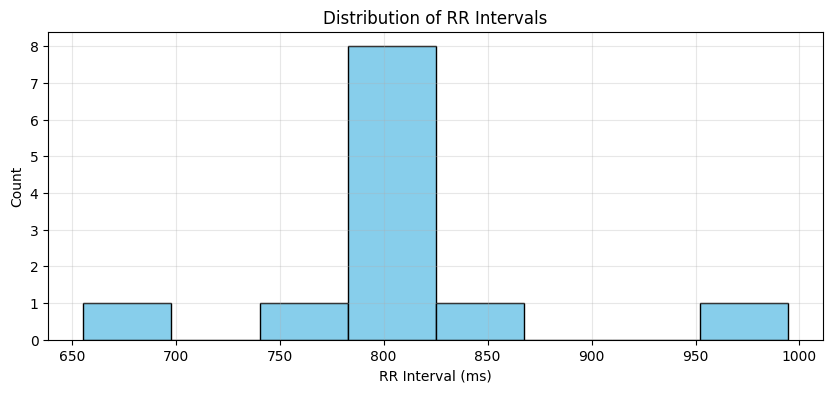

In [32]:
# RR Interval Histogram - Corrected Axis

plt.figure(figsize=(10, 4))
plt.hist(rr_ms, bins=8, color='skyblue', edgecolor='black')
plt.title('Distribution of RR Intervals')
plt.xlabel('RR Interval (ms)')
plt.ylabel('Count')
plt.grid(True, alpha=0.3)
plt.show()

In [33]:
# Final HRV Report

import numpy as np

diff_rr = np.diff(rr_ms)
rmssd = np.sqrt(np.mean(diff_rr**2))
pnn50 = np.sum(np.abs(diff_rr) > 50) / len(diff_rr) * 100
heart_rate = 60000 / np.mean(rr_ms)

print("===== FINAL HRV REPORT =====")
print(f"Heart Rate: {heart_rate:.1f} bpm")
print(f"Mean RR: {np.mean(rr_ms):.2f} ms")
print(f"SDNN: {np.std(rr_ms):.2f} ms")
print(f"RMSSD: {rmssd:.2f} ms")
print(f"pNN50: {pnn50:.1f} %")
print(f"Total Beats: {len(peaks)} in 10 seconds")

===== FINAL HRV REPORT =====
Heart Rate: 74.4 bpm
Mean RR: 806.25 ms
SDNN: 71.94 ms
RMSSD: 123.34 ms
pNN50: 27.3 %
Total Beats: 13 in 10 seconds


In [35]:
# Conclusion

print("""
Conclusion:
In this project, we analyzed a 10-second ECG signal sampled at 360 Hz.
We successfully detected 13 R-peaks using the SciPy find_peaks algorithm.
The average heart rate was 74.4 bpm, which is within the normal resting range (60-100 bpm).
The HRV analysis showed a Mean RR of 806.25 ms, SDNN of 71.94 ms, and RMSSD of 123.34 ms.
""")


Conclusion:
In this project, we analyzed a 10-second ECG signal sampled at 360 Hz.
We successfully detected 13 R-peaks using the SciPy find_peaks algorithm.
The average heart rate was 74.4 bpm, which is within the normal resting range (60-100 bpm).
The HRV analysis showed a Mean RR of 806.25 ms, SDNN of 71.94 ms, and RMSSD of 123.34 ms.

